# Lab 1 – Sentiment Analysis Using Traditional Machine Learning
PUSL3205 – Large Language Models and Generative AI

In [1]:
import pandas as pd 
import numpy as np 
import re 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import urllib.request, zipfile, os

url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(url, "data/data.zip")
zipfile.ZipFile("data/data.zip").extractall("data")
os.listdir("data/sentiment labelled sentences")

['.DS_Store',
 'amazon_cells_labelled.txt',
 'readme.txt',
 'yelp_labelled.txt',
 'imdb_labelled.txt']

In [3]:
folder = "data/sentiment labelled sentences/"

amazon = pd.read_csv(folder + "amazon_cells_labelled.txt",
                     sep="\t", header=None,
                     names=["text", "label"], quoting=3)
amazon.head()

,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [4]:
imdb = pd.read_csv(folder + "imdb_labelled.txt",
                   sep="\t", header=None,
                   names=["text", "label"], quoting=3)

yelp = pd.read_csv(folder + "yelp_labelled.txt",
                   sep="\t", header=None,
                   names=["text", "label"], quoting=3)

print(amazon.shape, imdb.shape, yelp.shape)

(1000, 2) (1000, 2) (1000, 2)


In [5]:
amazon["source"] = "amazon"
imdb["source"] = "imdb"
yelp["source"] = "yelp"

df = pd.concat([amazon, imdb, yelp], ignore_index=True)
df.head()

,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


In [6]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nLabel counts:\n", df["label"].value_counts())

Shape: (3000, 3)

Missing values:
 text      0
label     0
source    0
dtype: int64

Label counts:
 label
0    1500
1    1500
Name: count, dtype: int64


**Task 1 summary:** The dataset contains 3,000 sentences from Amazon, IMDb and Yelp (1,000 each).
Label 1 = positive, 0 = negative. There are 1,500 of each, so the classes are balanced, and there are no missing values.

## Task 2 – Text Preprocessing

In [7]:
def clean_text(text):
    text = text.lower()                        
    text = re.sub(r"[^a-z\s]", " ", text)      
    text = re.sub(r"\s+", " ", text).strip()   
    return text


clean_text("  This Phone is GREAT!!! 10/10 :)  ")

'this phone is great'

In [8]:
df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head(10)

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


In [9]:
pd.set_option("display.max_colwidth", None)   
df[["text", "clean_text"]].sample(5, random_state=1)

,text,clean_text
1957,"It showed exactly how the government and the scientist argued for humanity and the reasons of the ""gadget"".",it showed exactly how the government and the scientist argued for humanity and the reasons of the gadget
2087,All I have to say is the food was amazing!!!,all i have to say is the food was amazing
1394,"(My mother and brother had to do this)When I saw Robert Ryan portraying this type of man, it was a very good imitation of this type of individual, and I was impressed.",my mother and brother had to do this when i saw robert ryan portraying this type of man it was a very good imitation of this type of individual and i was impressed
1520,It is zillion times away from reality.,it is zillion times away from reality
1098,Ursula Burton's portrayal of the nun is both touching and funny at the same time with out making fun of nuns or the church.,ursula burton s portrayal of the nun is both touching and funny at the same time with out making fun of nuns or the church


**Observation:** After preprocessing, all text is lowercase and punctuation, numbers and extra spaces are removed.
For example, "Good case, Excellent value." becomes "good case excellent value".
This makes words like "Great" and "great!" count as the same word.

## Task 3 – Exploring the Text Data

In [10]:
print("POSITIVE examples:")
for t in df[df["label"] == 1]["text"].head(5):
    print(" +", t)

print("\nNEGATIVE examples:")
for t in df[df["label"] == 0]["text"].head(5):
    print(" -", t)

POSITIVE examples:
 + Good case, Excellent value.
 + Great for the jawbone.
 + The mic is great.
 + If you are Razr owner...you must have this!
 + And the sound quality is great.

NEGATIVE examples:
 - So there is no way for me to plug it in here in the US unless I go by a converter.
 - Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
 - I have to jiggle the plug to get it to line up right to get decent volume.
 - If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.
 - Needless to say, I wasted my money.


In [11]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS) - {"not", "no", "never", "nor"}
print(len(stop_words), "stopwords")

314 stopwords


In [12]:
from collections import Counter

def top_words(texts, n=15):
    words = []
    for t in texts:
        words += [w for w in t.split() if w not in stop_words]
    return Counter(words).most_common(n)

pos_words = top_words(df[df["label"] == 1]["clean_text"])
neg_words = top_words(df[df["label"] == 0]["clean_text"])

print("Top positive words:", pos_words)
print("\nTop negative words:", neg_words)

Top positive words: [('great', 201), ('good', 178), ('s', 148), ('film', 105), ('phone', 88), ('movie', 86), ('t', 65), ('best', 63), ('food', 60), ('place', 58), ('like', 56), ('not', 56), ('love', 56), ('really', 56), ('service', 55)]

Top negative words: [('not', 250), ('t', 216), ('s', 112), ('bad', 100), ('movie', 96), ('phone', 80), ('like', 69), ('just', 66), ('food', 66), ('don', 64), ('time', 62), ('no', 61), ('film', 58), ('place', 56), ('good', 53)]


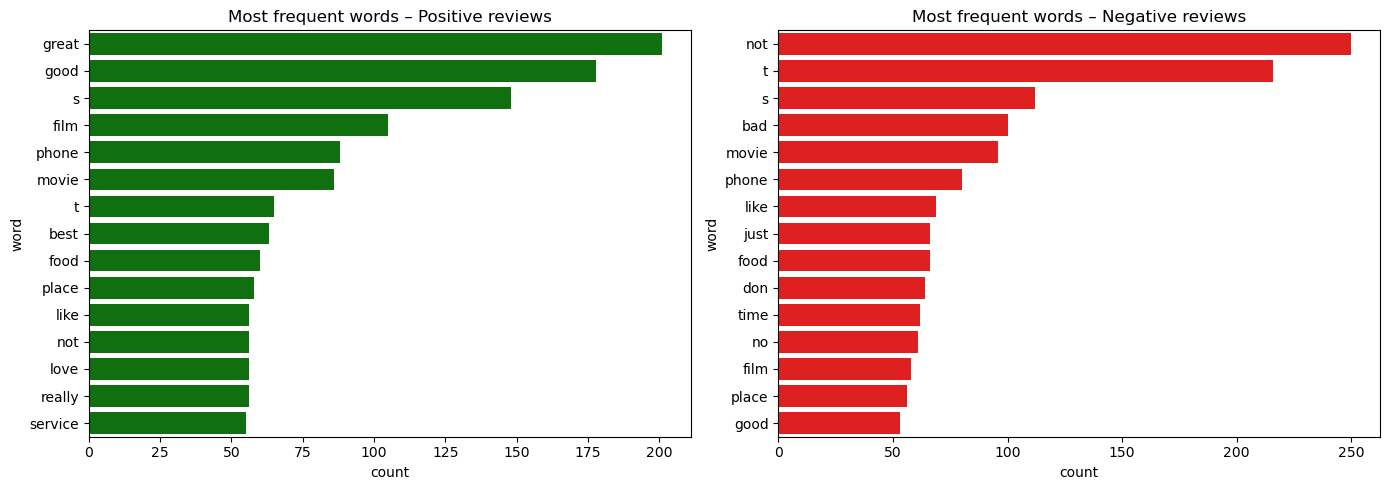

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pos_df = pd.DataFrame(pos_words, columns=["word", "count"])
neg_df = pd.DataFrame(neg_words, columns=["word", "count"])

sns.barplot(data=pos_df, x="count", y="word", ax=axes[0], color="green")
axes[0].set_title("Most frequent words – Positive reviews")

sns.barplot(data=neg_df, x="count", y="word", ax=axes[1], color="red")
axes[1].set_title("Most frequent words – Negative reviews")

plt.tight_layout()
plt.show()

**Observation:** Positive reviews often contain words like "great", "good", "love" and "best".
Negative reviews contain words like "not", "bad", "don't" and "waste".
Some words such as "movie", "food" and "phone" appear in both, because they describe the topic rather than the sentiment.

## Task 4 – Split the Dataset

In [14]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape[0], "sentences")
print("Test set:", X_test.shape[0], "sentences")

Training set: 2400 sentences
Test set: 600 sentences


## Task 5 – Bag of Words (BoW) Representation

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

X_train_bow = vectorizer.fit_transform(X_train)   # learn vocabulary from TRAINING data only
X_test_bow = vectorizer.transform(X_test)         # use the same vocabulary on test data

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Training matrix shape:", X_train_bow.shape)
print("Test matrix shape:", X_test_bow.shape)

Vocabulary size: 4479
Training matrix shape: (2400, 4479)
Test matrix shape: (600, 4479)


In [16]:
sample = ["the food was good", "the food was not good"]
demo = CountVectorizer().fit(sample)
pd.DataFrame(demo.transform(sample).toarray(),
             columns=demo.get_feature_names_out(),
             index=sample)

,food,good,not,the,was
the food was good,1,1,0,1,1
the food was not good,1,1,1,1,1


**Explanation:** Bag of Words turns each sentence into a vector of word counts.
The vectorizer is fitted only on the training data to avoid data leakage; the test data is only transformed.
BoW ignores word order, so "not good" and "good not" look the same.

## Task 6 – Train Machine Learning Models

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Naive Bayes": MultinomialNB()
}

for name, model in models.items():
    model.fit(X_train_bow, y_train)
    print(name, "trained ✔")

Logistic Regression trained ✔
Linear SVM trained ✔
Naive Bayes trained ✔


In [18]:
lr = models["Logistic Regression"]
words = vectorizer.get_feature_names_out()
coefs = pd.Series(lr.coef_[0], index=words).sort_values()

print("Most NEGATIVE words:\n", coefs.head(10))
print("\nMost POSITIVE words:\n", coefs.tail(10))

Most NEGATIVE words:
 poor             -2.244284
bad              -2.231539
worst            -2.182772
not              -1.835545
awful            -1.700755
terrible         -1.618369
disappointment   -1.500936
then             -1.499087
disappointing    -1.424855
stupid           -1.401141
dtype: float64

Most POSITIVE words:
 nice         1.680440
happier      1.686767
good         1.715112
loved        1.738730
delicious    1.781631
excellent    1.819951
awesome      1.844077
best         1.863318
love         2.050772
great        2.939876
dtype: float64


**Explanation:** Three models were trained on the Bag of Words features: Logistic Regression, Linear SVM and Naive Bayes.
The Logistic Regression weights show the model learned sensible words, e.g. positive words like "great" and negative words like "bad".

## Task 7 – Evaluate Model Performance

In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
for name, model in models.items():
    y_pred = model.predict(X_test_bow)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.822,0.804,0.850,0.827
1,Linear SVM,0.810,0.784,0.857,0.818
2,Naive Bayes,0.812,0.805,0.823,0.814


In [20]:
from sklearn.metrics import classification_report

best = models["Logistic Regression"]
y_pred = best.predict(X_test_bow)
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

              precision    recall  f1-score   support

    Negative       0.84      0.79      0.82       300
    Positive       0.80      0.85      0.83       300

    accuracy                           0.82       600
   macro avg       0.82      0.82      0.82       600
weighted avg       0.82      0.82      0.82       600



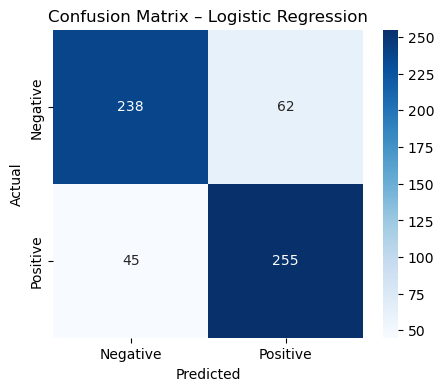

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Logistic Regression")
plt.show()

**Observation:** All three models achieved around 81–82% accuracy. The best model was Logistic Regression with an accuracy of 0.822 and an F1 score of 0.827, slightly ahead of Naive Bayes (0.812 accuracy, F1 0.814) and Linear SVM (0.810 accuracy, F1 0.818).
The confusion matrix shows that 493 out of 600 test sentences were classified correctly. Most errors were negative reviews predicted as positive (62), compared to 45 positive reviews predicted as negative.
This matches the classification report: recall for Negative (0.79) is lower than for Positive (0.85). This may be because some negative reviews contain positive words (e.g. "not good") or sarcasm, which Bag of Words cannot understand.

## Task 8 – Test the Model with New Sentences

In [22]:
new_sentences = [
    "This phone is amazing, I love it!",
    "Worst movie I have ever seen.",
    "The food was okay but the service was terrible.",
    "Not bad at all.",
    "I expected much more from this restaurant."
]

clean_new = [clean_text(s) for s in new_sentences]
new_bow = vectorizer.transform(clean_new)
preds = best.predict(new_bow)

for s, p in zip(new_sentences, preds):
    print("Positive 😊" if p == 1 else "Negative 😞", "→", s)

Positive 😊 → This phone is amazing, I love it!
Negative 😞 → Worst movie I have ever seen.
Negative 😞 → The food was okay but the service was terrible.
Negative 😞 → Not bad at all.
Negative 😞 → I expected much more from this restaurant.


**Observation:** The model correctly classified 4 out of 5 new sentences. Clear sentences such as "This phone is amazing, I love it!" (Positive) and "Worst movie I have ever seen." (Negative) were easy.
It also handled the mixed sentence "The food was okay but the service was terrible." correctly as Negative, because the strong word "terrible" outweighed "okay", and "I expected much more from this restaurant." was also correctly predicted as Negative.
However, "Not bad at all." was wrongly predicted as Negative, even though it is actually a positive comment. Bag of Words counts the word "bad" but ignores word order, so it cannot understand that "not" reverses the meaning.
This shows the main limitation of BoW: it counts words but does not understand context or negation. More advanced models such as transformers and LLMs handle this better.

## Conclusion
In this lab, 3,000 sentences from Amazon, IMDb and Yelp were preprocessed, converted to Bag of Words vectors and used to train three ML models.
Logistic Regression performed best with 82.2% accuracy and an F1-score of 0.827.
Traditional ML with BoW works well for clear sentiment, but struggles with negation (e.g. "Not bad at all"), sarcasm and context, which motivates the use of word embeddings and large language models in later labs.